# Yukon River discharge trends at Pilot Station (USGS 15565447)

Supplemental figure + the numbers cited in the discussion ("annual discharge rising ~12%/decade
over 2002-2025, led by winter flows +24%/decade"). Self-contained: streams the public USGS
daily-values record, converts to m3/s, fits Theil-Sen + AR(1)-corrected Mann-Kendall (the
paper's standard estimator) to annual and winter (Jan-Mar) means for the full record
(1976-2025, dashed) and the satellite era (2002-2025, solid), with near-complete-year coverage
filters (>=300 days annual, >=80 winter days). Figure -> `paper_figures/`.
Runs anywhere; only needs numpy/pandas/scipy/matplotlib + internet.

Context: Brabets & Walvoord (2009) found annual flow roughly unchanged through 2005 — the
increase here is concentrated in the last two decades, led by the groundwater-fed winter season
(cf. Walvoord & Striegl 2007; Liu et al. 2022). Note the correlation analyses in
`09_bering-and-anadyr-caches.ipynb` (discharge vs adg anomalies; all null) are a separate,
interannual-scale question.

In [ ]:
import io, urllib.request
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, norm

plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "figure.titlesize": 18,
})

CFS_TO_M3S = 0.0283168

url = ("https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=15565447"
       "&parameterCd=00060&startDT=1975-01-01")
raw = urllib.request.urlopen(url, timeout=90).read().decode()
q = pd.read_csv(io.StringIO(raw), sep="\t", comment="#").iloc[1:]
dcol = [c for c in q.columns if c.endswith("_00060_00003")][0]
q = pd.DataFrame({"m3s": pd.to_numeric(q[dcol], errors="coerce").values * CFS_TO_M3S},
                 index=pd.to_datetime(q["datetime"].values)).dropna()

def _lag1(r):
    a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def ts_mk(years, y):
    v = np.isfinite(y); x, y = np.asarray(years, float)[v], np.asarray(y, float)[v]
    s, ic, lo, hi = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    sl, icc = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + icc))
    ne = len(x) * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else len(x)
    p = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2 * ne + 5) / (9 * ne * (ne - 1)))))) if ne > 4 else np.nan
    return s, ic, p

cnt = q["m3s"].resample("YS").count()
ann = q["m3s"].resample("YS").mean()[cnt >= 300]          # require near-complete years
ann.index = ann.index.year
ann = ann[(ann.index >= 1976) & (ann.index <= 2025)]
wq = q["m3s"][q.index.month.isin([1, 2, 3])]
wcnt = wq.resample("YS").count()
win = wq.resample("YS").mean()[wcnt >= 80]                # require >=80 of ~90 winter days
win.index = win.index.year
win = win[(win.index >= 1976) & (win.index <= 2025)]

fig, axes = plt.subplots(2, 1, figsize=(10.5, 9.2), sharex=True)
panels = [("a  Annual mean discharge", ann, axes[0]),
          ("b  Winter (Jan–Mar) mean discharge", win, axes[1])]
for title, ser, ax in panels:
    mon = q["m3s"].resample("MS").mean() if ax is axes[0] else \
          q["m3s"][q.index.month.isin([1,2,3])].resample("MS").mean()
    ax.plot(mon.index.year + (mon.index.month - 0.5) / 12, mon.values,
            color="#9ecae1", lw=0.7, alpha=0.8, zorder=1)
    ax.plot(ser.index, ser.values, "o", color="black", ms=4, zorder=3)
    for (a, b), color, ls in [((1976, 2025), "#4477aa", "--"), ((2002, 2025), "#d6602c", "-")]:
        s = ser[(ser.index >= a) & (ser.index <= b)]
        sl, ic, p = ts_mk(s.index.values, s.values)
        xs = np.array([a, b], float)
        base = np.nanmean(s.values)
        sig = p < 0.05
        ax.plot(xs, sl * xs + ic, ls, color=color if sig else "#999999", lw=2, zorder=4)
        lbl = f"{a}–{b}: {100*sl*10/base:+.1f}%/dec, p{'<0.001' if p<0.001 else f'={p:.3f}'}"
        ax.annotate(lbl, xy=(0.02, 0.92 if color == "#4477aa" else 0.82),
                    xycoords="axes fraction", fontsize=14,
                    color=color if sig else "#777777")
    ax.set_title(title, loc="left", fontsize=17)
    ax.set_ylabel("discharge (m$^3$ s$^{-1}$)")
    ax.grid(alpha=0.25)
axes[1].set_xlabel("year")
axes[1].set_xlim(1975, 2027)
fig.suptitle("Yukon River discharge at Pilot Station (USGS 15565447)", fontsize=18)
fig.tight_layout()
out = "ADD_YOUR_PATH"  # add your path
fig.savefig(out, dpi=200, bbox_inches="tight")
print("saved", out)
for name, ser in [("annual", ann), ("winter", win)]:
    for a, b in [(1976, 2025), (2002, 2025)]:
        s = ser[(ser.index >= a) & (ser.index <= b)]
        sl, ic, p = ts_mk(s.index.values, s.values)
        base = np.nanmean(s.values)
        print(f"{name} {a}-{b}: {sl*10:+.0f} m3/s/dec ({100*sl*10/base:+.1f}%/dec) p={p:.4f}")


---

# Part B — Fig. S8: browning attribution figures

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# Browning attribution — publication figures

Reproduces the paper-ready versions of the key figures from the source-of-browning analysis:

* **Fig. 1** — study region map (boxes A/B/C, DBO 2, Yukon outflow, ACC pathway)
* **Fig. 2** — K$_d$(490) 8-day box-mean anomalies with Theil–Sen trends (the primary analysis)
* **Fig. 3** — a$_{dg}$(443), same layout
* **Fig. 4** — annual anomaly bars (both products × three boxes)
* **Fig. 5** — the co-variability gradient: box↔DBO 2 correlations with 95% CIs + the box C scatter

Style follows Science/Nature figure conventions: Helvetica/Arial ≤7 pt, thin axes with top/right
spines removed, no in-figure titles (caption drafts are in the markdown below each figure),
lowercase bold panel letters, Okabe–Ito colorblind-safe region colors (validated: every region is
also direct-labeled, and DBO 2 carries a dashed linestyle as secondary encoding), figures sized to
journal columns (89 mm / 183 mm), fonts embedded as TrueType (fonttype 42), saved as vector PDF +
600 dpi PNG into `paper_figures/`. Dense scatters are rasterized inside the vector PDFs to keep
file sizes sane.

**Prerequisites** (run from the folder that holds the caches): `bering_full_cache/` (weekly
series; ~3 min to load) and `ease2_output/ease2_region_means_ckpt.pkl` (correlation series;
instant). Stats are recomputed inline with the standard `dbo_weekly.trends` recipe, so the numbers
printed here should exactly match `bering_box_output/trend_summary.csv` and
`ease2_output/ease2_correlation_table.csv`.

In [1]:
import pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import theilslopes, kendalltau, norm, t as tdist

warnings.filterwarnings("ignore", category=RuntimeWarning)

## Style

In [2]:
MM = 1 / 25.4
SINGLE, DOUBLE = 89 * MM, 183 * MM          # Nature column widths

REGION_COLOR = {"A": "#0072B2", "B": "#E69F00", "C": "#009E73", "DBO2": "#CC79A7"}
POS, NEG = "#B2182B", "#2166AC"             # diverging bar pair (neutral gray midline)
INK, MUTED, LAND = "#1a1a1a", "#6e6e6e", "#ececec"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "figure.dpi": 130, "savefig.dpi": 600,
})

FIGDIR = Path("paper_figures"); FIGDIR.mkdir(exist_ok=True)

def panel_letter(ax, letter, dx=-0.04, dy=1.01):
    ax.text(dx, dy, letter, transform=ax.transAxes,
            fontsize=8, fontweight="bold", va="bottom", ha="right")

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"{name}.{ext}", bbox_inches="tight", pad_inches=0.02)
    print("saved:", FIGDIR / name, "(.pdf + .png)")

## Data + statistics
Weekly box series rebuilt from `bering_full_cache/` (primary analysis); EASE-2 region-mean series
loaded from the checkpoint pickle (correlation figure). Trend recipe verbatim from
`the DBO weekly-pipeline trend recipe (not included)`.

In [3]:
# --- geometry ---------------------------------------------------------------------------
BOXES = {
    "A": dict(lat=(57.7, 59.7), lon=(-171.5, -166.5)),
    "B": dict(lat=(60.2, 62.2), lon=(-170.5, -165.5)),
    "C": dict(lat=(62.4, 64.4), lon=(-169.0, -164.0)),
}
DBO2_RING = [(65.107747, -170.865176), (65.097001, -167.859549),
             (64.481828, -167.907758), (64.493658, -170.840669)]
PRODUCTS = {
    "kd490":  dict(label=r"$K_d$(490)",    unit=r"m$^{-1}$"),
    "adg443": dict(label=r"$a_{dg}$(443)", unit=r"m$^{-1}$"),
}
CACHE = Path("bering_full_cache")
EASE_CKPT = Path("ease2_output/ease2_region_means_ckpt.pkl")
to360 = lambda lon: lon + 360.0 if lon < 0 else lon

# --- trend / correlation recipe (dbo_weekly.trends) ---------------------------------------
def _lag1(r):
    r = np.asarray(r, float)
    a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def theilsen_mk_ar1(x, y, minn=8):
    v = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x, float)[v], np.asarray(y, float)[v]
    n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, p_adj=np.nan, phi=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1)
    phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2 * n_eff + 5) / (9 * n_eff * (n_eff - 1))))))
             if n_eff > 4 else np.nan)
    return dict(slope=float(slope), intercept=float(intercept), p_adj=float(p_adj),
                phi=float(phi), n=n)

def corr_ar1(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y)
    x, y = x[v], y[v]
    n = len(x)
    if n < 10:
        return dict(r=np.nan, p=np.nan, n=n, n_eff=np.nan)
    r = float(np.corrcoef(x, y)[0, 1])
    p1, p2 = _lag1(x - x.mean()), _lag1(y - y.mean())
    n_eff = float(np.clip(n * (1 - p1 * p2) / (1 + p1 * p2) if abs(p1 * p2) < 1 else n, 3, n))
    tstat = r * np.sqrt((n_eff - 2) / max(1 - r ** 2, 1e-12))
    return dict(r=r, p=float(2 * (1 - tdist.cdf(abs(tstat), df=n_eff - 2))), n=n, n_eff=n_eff)

def fisher_ci(r, n_eff, z=1.96):
    zz = np.arctanh(r)
    se = 1 / np.sqrt(max(n_eff - 3, 4))
    return float(np.tanh(zz - z * se)), float(np.tanh(zz + z * se))

def granule_times(fname):
    d0, d1 = fname.split(".")[1].split("_")
    t0, t1 = pd.Timestamp(d0), pd.Timestamp(d1)
    return t0, t1, t0 + (t1 - t0) / 2

# --- weekly cubes over the box area (primary analysis) ------------------------------------
UNION = dict(lat=(57.5, 65.2), lon360=(188.0, 196.5))
cubes = {}
for key in PRODUCTS:
    files = sorted((CACHE / key).glob("*.nc"))
    ds = xr.open_mfdataset(files, combine="nested", concat_dim="time", engine="h5netcdf",
                           data_vars="minimal", coords="minimal", compat="override")
    da = ds[key].sortby("time")
    lat_desc = da.lat.values[0] > da.lat.values[-1]
    lat_sl = slice(UNION["lat"][1], UNION["lat"][0]) if lat_desc else slice(*UNION["lat"])
    da = da.sel(lat=lat_sl, lon=slice(*UNION["lon360"])).load()
    ds.close()
    cubes[key] = da.isel(time=~pd.Index(da.time.values).duplicated())
    print(key, dict(cubes[key].sizes))

def weekly_box_anomaly(da, b):
    lat, lon = b["lat"], sorted(map(to360, b["lon"]))
    lat_desc = da.lat.values[0] > da.lat.values[-1]
    s = da.sel(lat=slice(lat[1], lat[0]) if lat_desc else slice(*lat),
               lon=slice(*lon)).mean(("lat", "lon"), skipna=True)
    t = pd.to_datetime(s.time.values)
    doy = t.dayofyear.values
    woy = np.minimum((doy - 1) // 8, 45)
    y = s.values.astype(float)
    clim = np.full(46, np.nan)
    for w in range(46):
        m = (woy == w) & np.isfinite(y)
        if m.sum() >= 5:
            clim[w] = np.nanmean(y[m])
    anom = y - clim[woy]
    dec = t.year.values + (doy - 1) / 365.25
    return dec, anom, t

WEEKLY = {}
for key in PRODUCTS:
    for bname, b in BOXES.items():
        dec, anom, t = weekly_box_anomaly(cubes[key], b)
        WEEKLY[(key, bname)] = dict(dec=dec, anom=anom, t=t,
                                    fit=theilsen_mk_ar1(dec, anom))
for (key, bname), w in WEEKLY.items():
    f = w["fit"]
    print(f"{key} box {bname}: {f['slope']*10:+.4f}/dec  p_adj={f['p_adj']:.4f}  n={f['n']}")

# --- EASE-2 monthly anomaly series (for the correlation figure) ---------------------------
ck = pickle.load(open(EASE_CKPT, "rb"))
EASE = {}
for key in PRODUCTS:
    fnames = sorted(ck[key])
    times = pd.DatetimeIndex([granule_times(fn)[2] for fn in fnames])
    for region in ["A", "B", "C", "DBO2"]:
        s = pd.Series([ck[key][fn][region][0] for fn in fnames], index=times).sort_index()
        m = s.resample("MS").mean()
        anom = m - m.index.month.map(m.groupby(m.index.month).mean())
        EASE[(key, region)] = anom
print("EASE-2 monthly anomaly series loaded")

kd490 {'time': 1099, 'lat': 185, 'lon': 204}
adg443 {'time': 1099, 'lat': 185, 'lon': 204}
kd490 box A: +0.0066/dec  p_adj=0.0071  n=705
kd490 box B: +0.0080/dec  p_adj=0.0073  n=649
kd490 box C: +0.0105/dec  p_adj=0.0209  n=622
adg443 box A: +0.0007/dec  p_adj=0.6899  n=704
adg443 box B: +0.0044/dec  p_adj=0.0829  n=639
adg443 box C: +0.0066/dec  p_adj=0.0330  n=609
EASE-2 monthly anomaly series loaded


## Fig. 1 — study region

**Caption draft:** *Study region in the northern Bering Sea. Boxes A–C span the eastern shelf from
south of Nunivak Island to the Chirikov Basin approaches; the Distributed Biological Observatory
site 2 (DBO 2, dashed) occupies the Chirikov Basin south of Bering Strait. The Yukon River enters
through a delta front adjacent to box C (triangle); the Alaska Coastal Current (ACC, arrow)
carries Yukon-influenced water northward through the eastern Chirikov Basin toward Bering Strait.*

saved: paper_figures/fig1_region_map (.pdf + .png)


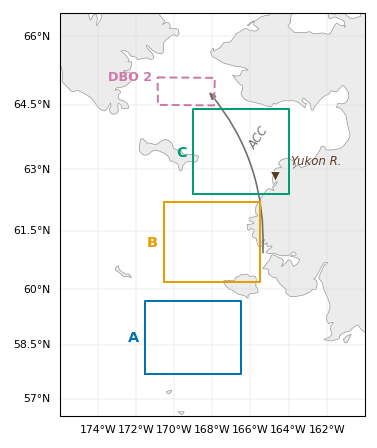

In [4]:
fig = plt.figure(figsize=(SINGLE, SINGLE * 1.15))
ax = plt.axes(projection=ccrs.Mercator(central_longitude=-168))
ax.set_extent([-176, -160, 56.5, 66.5], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor=LAND, edgecolor="none", zorder=1)
ax.coastlines("50m", lw=0.4, color="#9a9a9a", zorder=2)
gl = ax.gridlines(draw_labels=True, lw=0.25, color="#d9d9d9", ls="-")
gl.top_labels = gl.right_labels = False
gl.xlabel_style = gl.ylabel_style = {"size": 6}

for name, b in BOXES.items():
    (lat0, lat1), (lon0, lon1) = b["lat"], b["lon"]
    ax.plot([lon0, lon1, lon1, lon0, lon0], [lat0, lat0, lat1, lat1, lat0],
            transform=ccrs.PlateCarree(), color=REGION_COLOR[name], lw=1.1, zorder=5)
    ax.text(lon0 - 0.35, (lat0 + lat1) / 2, name, transform=ccrs.PlateCarree(),
            fontsize=8, fontweight="bold", color=REGION_COLOR[name],
            ha="right", va="center", zorder=5)

ring = DBO2_RING + [DBO2_RING[0]]
ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
        color=REGION_COLOR["DBO2"], lw=1.1, ls=(0, (4, 2)), zorder=5)
ax.text(DBO2_RING[0][1] - 0.3, DBO2_RING[0][0], "DBO 2", transform=ccrs.PlateCarree(),
        fontsize=7, fontweight="bold", color=REGION_COLOR["DBO2"], va="center",
        ha="right", zorder=5)

ax.plot(-164.70, 62.85, marker="v", ms=5, color="#5c3a1e",
        markeredgecolor="white", markeredgewidth=0.5, transform=ccrs.PlateCarree(), zorder=6)
ax.text(-163.85, 63.1, "Yukon R.", transform=ccrs.PlateCarree(),
        fontsize=6.5, color="#5c3a1e", fontstyle="italic", zorder=6)

ax.annotate("", xy=(-168.3, 64.85), xytext=(-165.35, 60.85),
            xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            textcoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            arrowprops=dict(arrowstyle="-|>,head_width=0.18,head_length=0.45",
                            connectionstyle="arc3,rad=0.2", color=MUTED, lw=0.9), zorder=4)
ax.text(-166.15, 63.5, "ACC", transform=ccrs.PlateCarree(),
        fontsize=6.5, color=MUTED, fontstyle="italic", rotation=55, zorder=4)

save(fig, "fig1_region_map")
plt.show()

## Fig. 2 — K$_d$(490) box-mean anomaly trends (primary analysis)

**Caption draft:** *Diffuse attenuation at 490 nm over the eastern Bering shelf, 2002–2026. The pale trace shows 8-day box-mean anomalies relative to each box's composite-of-year climatology (MODIS-Aqua L3m,
4 km); black dots are annual means (years with ≥15 composites). Bold brown lines with shading show
Theil–Sen fits and their 95% confidence bands where the AR(1)-corrected Mann–Kendall test is
significant (P < 0.05); grey dashed lines show non-significant fits. Slopes and P-values are
given per panel. K$_d$(490) increases significantly in all three boxes.
Panels are ordered north (top) to south (bottom); note independent y-scales. A small number of
extreme positive anomalies lie beyond the plotted range.*

saved: paper_figures/fig2_kd490_trends (.pdf + .png)


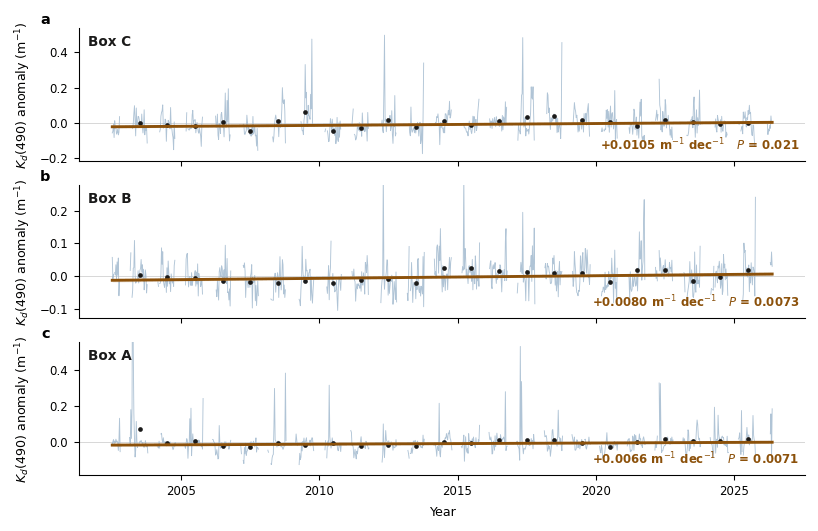

In [5]:
TREND_SIG = "#8C510A"      # browning accent: significant upward trend
DATA_LINE = "#9db6cc"      # pale 8-day anomaly trace

def anomaly_trend_figure(key, name):
    fig, axes = plt.subplots(3, 1, figsize=(DOUBLE, DOUBLE * 0.62), sharex=True)
    lab, unit = PRODUCTS[key]["label"], PRODUCTS[key]["unit"]
    for ax, bname, letter in zip(axes, ["C", "B", "A"], "abc"):
        w = WEEKLY[(key, bname)]
        dec, anom, t, f = w["dec"], w["anom"], w["t"], w["fit"]
        sig = np.isfinite(f["p_adj"]) and f["p_adj"] < 0.05

        ax.axhline(0, color="#d5d5d5", lw=0.5, zorder=1)
        # pale continuous trace of the 8-day anomalies (gaps break the line naturally)
        ax.plot(dec, anom, "-", color=DATA_LINE, lw=0.5, alpha=0.8,
                rasterized=True, zorder=2)
        # black dots: annual means (>=15 composites)
        df = pd.DataFrame(dict(yr=t.year, anom=anom)).dropna()
        g = df.groupby("yr")["anom"]
        am = g.mean()[g.size() >= 15]
        ax.plot(am.index + 0.5, am.values, "o", ms=2.6, color=INK,
                markeredgecolor="none", zorder=4)

        # Theil-Sen line: bold + 95%-CI band when significant, grey dashed when not
        xx = np.array([np.nanmin(dec), np.nanmax(dec)])
        v = np.isfinite(dec) & np.isfinite(anom)
        _, _, s_lo, s_hi = theilslopes(anom[v], dec[v], 0.95)
        x0 = dec[v].mean()
        y0 = f["intercept"] + f["slope"] * x0
        if sig:
            ax.fill_between(xx, y0 + s_lo * (xx - x0), y0 + s_hi * (xx - x0),
                            color=TREND_SIG, alpha=0.12, lw=0, zorder=3)
            ax.plot(xx, f["intercept"] + f["slope"] * xx, "-", color=TREND_SIG,
                    lw=1.6, zorder=5)
        else:
            ax.plot(xx, f["intercept"] + f["slope"] * xx, ls=(0, (5, 3)),
                    color="#9a9aa2", lw=1.3, zorder=5)

        lo, hi = np.nanpercentile(anom, [0.3, 99.7])
        pad = 0.10 * (hi - lo)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_ylabel(f"{lab} anomaly ({unit})")
        ax.text(0.012, 0.95, f"Box {bname}", transform=ax.transAxes, fontsize=7.5,
                fontweight="bold", color=INK, va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2))
        txt = (f"{f['slope']*10:+.4f} " + unit + r" dec$^{-1}$" +
               f"   $P$ = {f['p_adj']:.2g}")
        ax.text(0.992, 0.06, txt, transform=ax.transAxes, fontsize=6.5,
                va="bottom", ha="right", color=TREND_SIG if sig else MUTED,
                fontweight="bold" if sig else "normal",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2))
        panel_letter(ax, letter)
    axes[-1].set_xlabel("Year")
    axes[-1].set_xticks(np.arange(2005, 2026, 5))
    fig.align_ylabels(axes)
    fig.subplots_adjust(hspace=0.18)
    save(fig, name)
    return fig

anomaly_trend_figure("kd490", "fig2_kd490_trends")
plt.show()

## Fig. 3 — a$_{dg}$(443) box-mean anomaly trends

**Caption draft:** *As Fig. 2, for absorption by colored dissolved and detrital material at 443 nm
(GIOP a$_{dg}$). The increase is significant only in box C, adjacent to the Yukon delta, and trend
magnitude declines southward (C > B > A), consistent with a riverine source region.*

saved: paper_figures/fig3_adg443_trends (.pdf + .png)


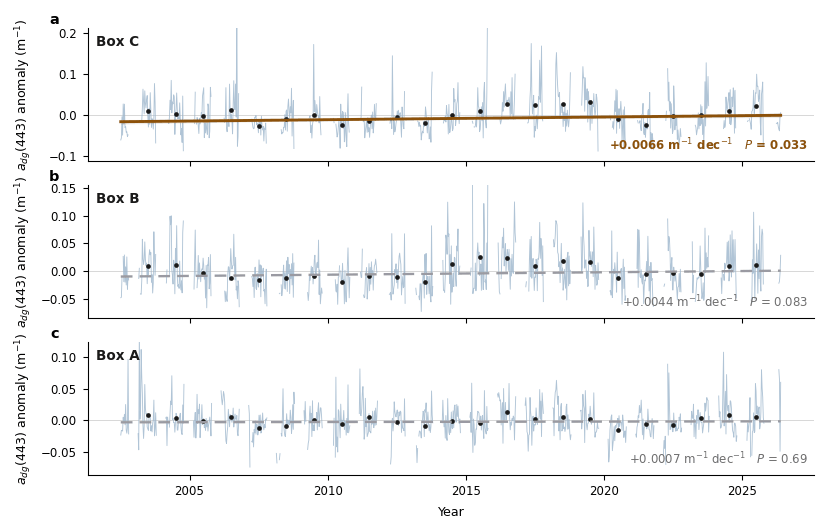

In [6]:
anomaly_trend_figure("adg443", "fig3_adg443_trends")
plt.show()

## Fig. 4 — annual anomaly bars

**Caption draft:** *Annual means of the 8-day box-mean anomalies for a$_{dg}$(443) (left) and
K$_d$(490) (right) in boxes C, B and A (top to bottom). Red (blue) bars denote years darker
(clearer) than the 2002–2026 climatology; faded bars are incomplete years (record starts July
2002; final year partial). Black line: 5-year centred running mean. Dashed line: Theil–Sen trend
fitted to the full 8-day anomaly series (Figs. 2–3).*

saved: paper_figures/fig4_annual_bars (.pdf + .png)


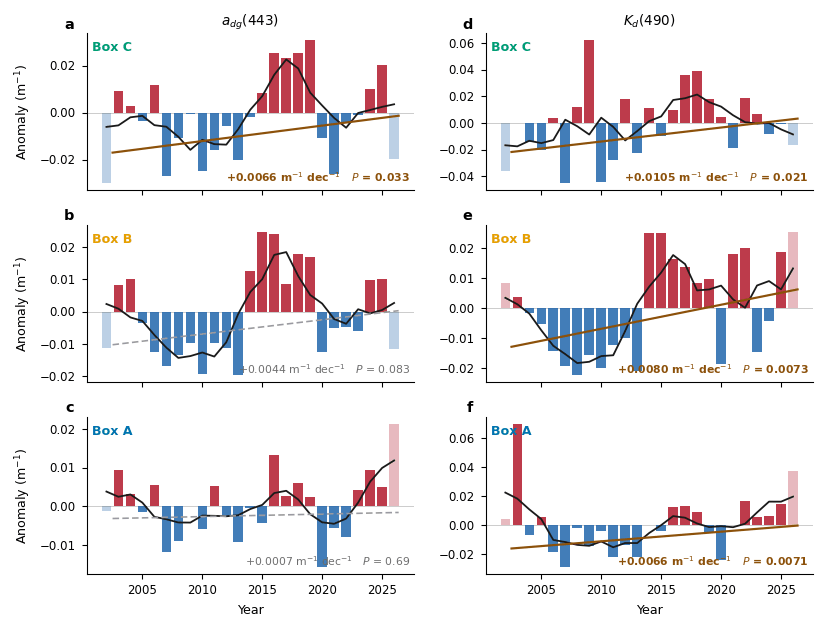

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(DOUBLE, DOUBLE * 0.75), sharex=True)
letters = iter("abcdef")
for j, key in enumerate(["adg443", "kd490"]):
    lab, unit = PRODUCTS[key]["label"], PRODUCTS[key]["unit"]
    for i, bname in enumerate(["C", "B", "A"]):
        ax = axes[i, j]
        w = WEEKLY[(key, bname)]
        f = w["fit"]
        df = pd.DataFrame(dict(yr=w["t"].year, anom=w["anom"])).dropna()
        g = df.groupby("yr")["anom"]
        am, n = g.mean(), g.size()

        bars = ax.bar(am.index, am.values, width=0.8,
                      color=[POS if v > 0 else NEG for v in am.values],
                      alpha=0.85, edgecolor="none", zorder=2)
        for patch, nn in zip(bars, n.values):
            if nn < 15:
                patch.set_alpha(0.3)
        roll = am.rolling(5, center=True, min_periods=3).mean()
        ax.plot(roll.index, roll.values, color=INK, lw=1.0, zorder=3)
        xx = np.array([w["dec"][np.isfinite(w["anom"])].min(),
                       w["dec"][np.isfinite(w["anom"])].max()])
        sig = np.isfinite(f["p_adj"]) and f["p_adj"] < 0.05
        if sig:
            ax.plot(xx, f["intercept"] + f["slope"] * xx, "-", color=TREND_SIG,
                    lw=1.2, zorder=3)
        else:
            ax.plot(xx, f["intercept"] + f["slope"] * xx, ls=(0, (4, 2)),
                    color="#9a9aa2", lw=0.9, zorder=3)
        ax.axhline(0, color="#c8c8c8", lw=0.5, zorder=1)
        ax.text(0.988, 0.04,
                f"{f['slope']*10:+.4f} " + unit + r" dec$^{-1}$" +
                f"   $P$ = {f['p_adj']:.2g}",
                transform=ax.transAxes, fontsize=6, va="bottom", ha="right",
                color=TREND_SIG if sig else MUTED,
                fontweight="bold" if sig else "normal", zorder=6,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2))

        ax.text(0.015, 0.95, f"Box {bname}", transform=ax.transAxes, fontsize=7,
                fontweight="bold", color=REGION_COLOR[bname], va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2))
        if i == 0:
            ax.set_title(lab, fontsize=7.5, pad=4)
        if j == 0:
            ax.set_ylabel(f"Anomaly ({unit})")
        panel_letter(ax, next(letters))
for ax in axes[-1]:
    ax.set_xlabel("Year")
    ax.set_xticks(np.arange(2005, 2026, 5))
fig.align_ylabels(axes[:, 0])
fig.subplots_adjust(hspace=0.22, wspace=0.22)
save(fig, "fig4_annual_bars")
plt.show()

## Methods text these figures commit you to

* Trends: Theil–Sen slopes on deseasonalized 8-day box-mean anomalies (composite-of-year
  climatology, ≥5 obs per 8-day slot); significance from two-sided Mann–Kendall with the
  Hamed–Rao-style AR(1) effective-sample-size correction. This is the **primary analysis**;
  monthly aggregation and EASE-2 regridding were run as sensitivity analyses and reproduce all
  slopes (see `ease2_output/ease2_trend_table.csv`).
* Data: MODIS-Aqua L3m 8-day 4 km (R2022.0), `Kd_490` and GIOP `adg_443`, July 2002 – present;
  final partial year flagged in Fig. 4.
* Driver null results available if a reviewer asks: Yukon discharge (annual, freshet,
  0–3-month lags) and open-water exposure (trendless; interannual correlation shown to be a
  sampling-composition artifact by a fixed-month test).

---

# Part C — Fig. S9: adg(443) teleconnection with DBO 2 (Spearman)

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# adg(443) teleconnection with DBO 2 — Spearman version

Self-contained rebuild of the teleconnection map from an earlier Pearson-correlation notebook (not included) (Anadyr-extended
domain), with **Spearman rank correlation** in place of Pearson. Every pixel's monthly adg(443) anomaly series
and the DBO 2 adg index are rank-transformed before correlating, so a few extreme months cannot dominate.
Significance is the same Bretherton et al. (1999) AR(1) effective-sample-size test, applied to the ranks.

**Runs from anywhere.** The setup cell searches the usual places (the working folder, `$HOME`, and `$HOME/ADD_YOUR_PATH/source-of-browning`) for two things the other notebooks already produced:

- `ease2_output/ease2_region_means_ckpt.pkl` — the DBO 2 adg index (EASE-2 polygon mean, 8-day)
- `bering_full_cache/adg443/*.nc` — the cached 8-day MODIS L3m adg(443) subsets (no re-streaming)

Outputs go to `tracing_output/`: `teleconnection_map_withanadyr_spearman.png/.pdf`, the field as
`teleconnection_adg_dbo2_withanadyr_spearman.nc`, and a per-box Pearson-vs-Spearman table (CSV).
Set `ALSO_PEARSON = True` (default) to recompute Pearson on the same cube for a side-by-side check;
it roughly doubles the ~5–10 min pixel loop.


In [ ]:
import pickle, warnings, time as _time
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import rankdata, t as tdist

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- locate inputs: the other notebooks wrote these either into the repo folder or flat in $HOME ----
HOME = Path.home()  # add your path
ROOTS = [Path.cwd(), Path.cwd() / "source-of-browning", HOME, HOME / "source-of-browning",
         HOME / "ADD_YOUR_PATH" / "source-of-browning", HOME / "ADD_YOUR_PATH"]
ROOTS = [r for r in dict.fromkeys(ROOTS) if r.exists()]

def _find_file(rel):
    for r in ROOTS:
        if (r / rel).exists():
            return r / rel
    hits = sorted(HOME.rglob(Path(rel).name))            # last resort: search the home tree
    return hits[0] if hits else None

def _find_dir(rel):
    for r in ROOTS:
        if (r / rel).is_dir() and any((r / rel).glob("*.nc")):
            return r / rel
    hits = [d for d in HOME.rglob(Path(rel).name) if d.is_dir() and any(d.glob("*.nc"))]
    return hits[0] if hits else None

CKPT  = _find_file("ease2_output/ease2_region_means_ckpt.pkl")
CACHE = _find_dir("bering_full_cache/adg443")
print("searched roots:", [str(r) for r in ROOTS])
print("DBO2 index checkpoint :", CKPT)
print("adg443 granule cache  :", CACHE, f"({len(list(CACHE.glob('*.nc')))} files)" if CACHE else "")
assert CKPT is not None,  ("ease2_region_means_ckpt.pkl not found under the roots above or anywhere in $HOME. "
                           "It is written by 09_bering-and-anadyr-caches.ipynb (cell 8); run that first.")
assert CACHE is not None, ("bering_full_cache/adg443 (with .nc files) not found. It is written by "
                           "09_bering-and-anadyr-caches.ipynb / 09_bering-and-anadyr-caches.ipynb; run that first.")

OUTDIR = CKPT.parent.parent / "tracing_output"; OUTDIR.mkdir(exist_ok=True)   # next to ease2_output/
ALSO_PEARSON = True          # recompute Pearson on the same cube for a side-by-side table
MIN_MONTHS   = 60            # pixels need >= this many valid months (same as the Pearson cell)
print("outputs ->", OUTDIR.resolve())

## 1. Config, boxes, and correlation helpers (recipes copied from the source notebook)

In [ ]:
BOXES = {                                        # Yukon-side boxes (lon in -180..180)
    "A": dict(lat=(57.7, 59.7), lon=(-171.5, -166.5)),
    "B": dict(lat=(60.2, 62.2), lon=(-170.5, -165.5)),
    "C": dict(lat=(62.4, 64.4), lon=(-169.0, -164.0)),
}
ANADYR_BOXES = {                                 # Anadyr-side boxes (lon360), from anadyr-side-phase1
    "AnadyrInner":  dict(lat=(63.6, 65.0), lon360=(176.5, 180.5)),
    "AnadyrOuter":  dict(lat=(61.8, 63.6), lon360=(174.0, 179.5)),
    "AnadyrStrait": dict(lat=(63.3, 64.7), lon360=(186.5, 189.2)),
}
DBO2_RING = [(65.107747, -170.865176), (65.097001, -167.859549),
             (64.481828, -167.907758), (64.493658, -170.840669)]
TELE_W = dict(lat=(57.5, 66.2), lon360=(173.0, 199.5))   # west edge covers AnadyrOuter (174E)
to360 = lambda lon: lon + 360.0 if lon < 0 else lon

def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def _ar1_test(x, y):
    """Pearson r of (x, y) with Bretherton et al. (1999) effective n; x, y already finite & aligned."""
    n = len(x)
    if n < 10 or np.nanstd(x) == 0 or np.nanstd(y) == 0:
        return dict(r=np.nan, p=np.nan, n=n, n_eff=np.nan)
    r = float(np.corrcoef(x, y)[0, 1])
    p1, p2 = _lag1(x - x.mean()), _lag1(y - y.mean())
    n_eff = float(np.clip(n * (1 - p1 * p2) / (1 + p1 * p2) if abs(p1 * p2) < 1 else n, 3, n))
    ts = r * np.sqrt((n_eff - 2) / max(1 - r ** 2, 1e-12))
    return dict(r=r, p=float(2 * (1 - tdist.cdf(abs(ts), df=n_eff - 2))), n=n, n_eff=n_eff)

def corr_ar1(x, y):
    """Pearson r, AR(1)-corrected p (identical to the source notebook)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y)
    return _ar1_test(x[v], y[v])

def spearman_ar1(x, y):
    """Spearman rho = Pearson on ranks; AR(1)-corrected p computed on the ranks."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y)
    if v.sum() < 10:
        return dict(r=np.nan, p=np.nan, n=int(v.sum()), n_eff=np.nan)
    return _ar1_test(rankdata(x[v]), rankdata(y[v]))       # ties -> average rank

def granule_times(fname):
    d0, d1 = fname.split(".")[1].split("_")
    t0, t1 = pd.Timestamp(d0), pd.Timestamp(d1)
    return t0, t1, t0 + (t1 - t0) / 2

def monthly_anom_from_series(s):
    m = s.resample("MS").mean()
    return m - m.index.month.map(m.groupby(m.index.month).mean())

# ---- DBO 2 adg index: 8-day EASE-2 polygon means -> monthly month-of-year anomaly ----------
ck = pickle.load(open(CKPT, "rb"))
fnames = sorted(ck["adg443"])
times  = pd.DatetimeIndex([granule_times(fn)[2] for fn in fnames])
idx_raw = pd.Series([ck["adg443"][fn]["DBO2"][0] for fn in fnames], index=times).sort_index()
IDX = monthly_anom_from_series(idx_raw)
print(f"DBO2 adg index: {IDX.notna().sum()} months, {IDX.index.min():%Y-%m} -> {IDX.index.max():%Y-%m}")

## 2. Load the cached adg(443) pixel stack, subset to the extended domain, monthly anomalies

In [ ]:
files = sorted(CACHE.glob("*.nc"))
print(f"{len(files)} cached granules")
ds = xr.open_mfdataset(files, combine="nested", concat_dim="time", engine="h5netcdf",
                       data_vars="minimal", coords="minimal", compat="override")
da = ds["adg443"].sortby("time")
lat_desc = da.lat.values[0] > da.lat.values[-1]
lat_sl = slice(TELE_W["lat"][1], TELE_W["lat"][0]) if lat_desc else slice(*TELE_W["lat"])
cube = da.sel(lat=lat_sl, lon=slice(*TELE_W["lon360"])).load()
ds.close()
cube = cube.isel(time=~pd.Index(cube.time.values).duplicated())
print("extended tele cube:", dict(cube.sizes))

mon  = cube.resample(time="MS").mean()
anom = mon.groupby("time.month") - mon.groupby("time.month").mean("time")
common = np.intersect1d(pd.to_datetime(anom.time.values), IDX.index)
A3  = anom.sel(time=common).values            # (time, lat, lon)
IDXV = IDX.reindex(pd.DatetimeIndex(common)).values
LON, LAT = np.meshgrid(cube.lon.values, cube.lat.values)
print(f"{len(common)} common months | grid {A3.shape[1:]}")

## 3. Per-pixel Spearman (and optional Pearson) correlation with the DBO 2 index

In [ ]:
ny, nx = A3.shape[1:]
RS = np.full((ny, nx), np.nan, np.float32); PS = np.full((ny, nx), np.nan, np.float32)
RP = np.full((ny, nx), np.nan, np.float32); PP = np.full((ny, nx), np.nan, np.float32)
t0 = _time.time(); done = 0
for j in range(ny):
    for i in range(nx):
        y = A3[:, j, i]
        if np.isfinite(y).sum() < MIN_MONTHS:
            continue
        c = spearman_ar1(IDXV, y); RS[j, i], PS[j, i] = c["r"], c["p"]
        if ALSO_PEARSON:
            c = corr_ar1(IDXV, y);  RP[j, i], PP[j, i] = c["r"], c["p"]
        done += 1
        if done % 20000 == 0:
            print(f"  {done:,} pixels ({_time.time()-t0:.0f}s)")
print(f"done: {done:,} pixels in {(_time.time()-t0)/60:.1f} min")

out = xr.Dataset(dict(rho=(("lat", "lon"), RS), p=(("lat", "lon"), PS)),
                 coords=dict(lat=cube.lat, lon=cube.lon),
                 attrs=dict(index="DBO2 monthly adg_443 anomaly (EASE-2 polygon mean)",
                            method="Spearman rho on rank-transformed monthly anomalies; "
                                   "Bretherton (1999) AR1 effective-n p on the ranks",
                            domain="extended west across the dateline to include the Gulf of Anadyr",
                            min_months=MIN_MONTHS, n_months=int(len(common))))
if ALSO_PEARSON:
    out["r_pearson"] = (("lat", "lon"), RP); out["p_pearson"] = (("lat", "lon"), PP)
out.to_netcdf(OUTDIR / "teleconnection_adg_dbo2_withanadyr_spearman.nc")
print("saved ->", OUTDIR / "teleconnection_adg_dbo2_withanadyr_spearman.nc")

## 4. Map (same furniture as the Pearson figure)

In [ ]:
fig = plt.figure(figsize=(13, 9.8))
ax = fig.add_axes([0.06, 0.16, 0.90, 0.78], projection=ccrs.Mercator(central_longitude=-174))
ax.set_extent([TELE_W["lon360"][0], TELE_W["lon360"][1], *TELE_W["lat"]], crs=ccrs.PlateCarree())
pm = ax.pcolormesh(cube.lon, cube.lat, RS, cmap="RdBu_r", vmin=-0.5, vmax=0.5,
                   transform=ccrs.PlateCarree(), zorder=2)
sigW = np.isfinite(PS) & (PS < 0.05)
ax.plot(LON[sigW][::4], LAT[sigW][::4], ".", color="k", ms=0.6, alpha=0.5,
        transform=ccrs.PlateCarree(), zorder=3)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#e7e5de", edgecolor="none", zorder=4)
ax.coastlines("50m", lw=0.5, color="#8a8a8a", zorder=5)

def _box360(lat0, lat1, lo0, lo1, label, ls="-"):
    ax.plot([lo0, lo1, lo1, lo0, lo0], [lat0, lat0, lat1, lat1, lat0],
            transform=ccrs.PlateCarree(), color="#444444", lw=1.2, ls=ls, zorder=6)
    ax.text(lo0 + 0.15, lat1 - 0.12, label, transform=ccrs.PlateCarree(),
            fontsize=9, fontweight="bold", color="#333333", va="top", zorder=7)

for bname, b in BOXES.items():
    _box360(*b["lat"], *map(to360, b["lon"]), bname)
for aname in ["AnadyrInner", "AnadyrStrait"]:                       # Outer dropped
    b = ANADYR_BOXES[aname]; _box360(*b["lat"], *b["lon360"], aname.replace("Anadyr", ""))
ring = DBO2_RING + [DBO2_RING[0]]
ax.plot([to360(p_[1]) for p_ in ring], [p_[0] for p_ in ring],
        transform=ccrs.PlateCarree(), color="#444444", lw=1.4, ls="--", zorder=6)
ax.text(to360(-170.7), 65.35, "DBO2", transform=ccrs.PlateCarree(),
        fontsize=9, fontweight="bold", color="#333333", zorder=7)
ax.plot(to360(-164.70), 62.85, marker="v", ms=8, color="#5c3a1e",
        markeredgecolor="white", transform=ccrs.PlateCarree(), zorder=7)   # Yukon mouth
ax.plot(177.5, 64.75, marker="v", ms=8, color="#5c3a1e",
        markeredgecolor="white", transform=ccrs.PlateCarree(), zorder=7)   # Anadyr mouth
gl = ax.gridlines(draw_labels=True, lw=0.3, color="#c8c8c8", ls=":")
gl.top_labels = gl.right_labels = False

# colorbar in its own axes: fig.colorbar(ax=ax) collapses a fixed-extent GeoAxes on mpl 3.11 / cartopy 0.25
cax = fig.add_axes([0.22, 0.07, 0.56, 0.025])
cb = fig.colorbar(pm, cax=cax, orientation="horizontal")
cb.set_label("Spearman ρ (pixel monthly adg anomaly vs DBO 2 adg index), stippled p_adj < 0.05")
ax.set_title("adg(443) teleconnection with DBO 2: Spearman rank correlation of adg(443) anomalies "
             "across the full inflow shelf")
out = OUTDIR / "teleconnection_map_withanadyr_spearman.png"
fig.savefig(out, dpi=150, bbox_inches="tight"); fig.savefig(out.with_suffix(".pdf"), bbox_inches="tight")
print("saved ->", out)
plt.show()

## 5. Per-box summary: Spearman vs Pearson

Median correlation and share of significant pixels inside each box. Expect the spatial pattern to match the Pearson map and the values near DBO 2 to drop slightly, since Pearson is inflated by shared extreme months.

In [ ]:
allboxes = {**{k: dict(lat=v["lat"], lon360=tuple(map(to360, v["lon"]))) for k, v in BOXES.items()},
            **ANADYR_BOXES}
rows = []
for name, b in allboxes.items():
    m = ((LAT >= b["lat"][0]) & (LAT <= b["lat"][1]) & (LON >= b["lon360"][0]) & (LON <= b["lon360"][1]))
    row = dict(box=name, n_pix=int(np.isfinite(RS[m]).sum()),
               spearman_median=np.nanmedian(RS[m]), pct_sig_spearman=100*np.nanmean(PS[m] < 0.05))
    if ALSO_PEARSON:
        row.update(pearson_median=np.nanmedian(RP[m]), pct_sig_pearson=100*np.nanmean(PP[m] < 0.05))
    rows.append(row)
tbl = pd.DataFrame(rows).set_index("box").round(3)
tbl.to_csv(OUTDIR / "teleconnection_box_summary_spearman.csv")
print(tbl.to_string())